# Analyse exploratoire des données

Journées simulées avec le contrôleur basal-bolus (référence) sur les 30 patients virtuels du simulateur UVA/Padova. Générées par `python -m src.data`.

In [1]:
import sys
sys.path.insert(0, '..')
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config
from src.simulator import patient_profile

df = pd.read_csv(config.DATA_DIR / 'simulations.csv', parse_dates=['time'])
df['category'] = df['patient'].str.split('#').str[0]
df.head()

,time,patient,seed,bg,cgm,cho,basal,bolus,insulin,lbgi,hbgi,controller,split,day,category
0,2026-01-01 06:03:00,adolescent#001,0,145.338643,153.242626,0.0,0.041807,0.0,0.041807,0.0,2.285547,basal_bolus,train,0,adolescent
1,2026-01-01 06:06:00,adolescent#001,0,146.130011,155.662574,0.0,0.041807,0.0,0.041807,0.0,2.383775,basal_bolus,train,0,adolescent
2,2026-01-01 06:09:00,adolescent#001,0,146.729809,156.486378,0.0,0.041807,0.0,0.041807,0.0,2.459244,basal_bolus,train,0,adolescent
3,2026-01-01 06:12:00,adolescent#001,0,147.191128,156.121665,0.0,0.041807,0.0,0.041807,0.0,2.517879,basal_bolus,train,0,adolescent
4,2026-01-01 06:15:00,adolescent#001,0,147.550790,154.957281,0.0,0.041807,0.0,0.041807,0.0,2.563946,basal_bolus,train,0,adolescent


## Structure et qualité des données

In [2]:
print(df.shape)
print(df.dtypes)
print('valeurs manquantes :', int(df.isna().sum().sum()))
df.groupby('split').agg(patients=('patient', 'nunique'), lignes=('bg', 'size'))

(41170, 15)
time          datetime64[ns]
patient               object
seed                   int64
bg                   float64
cgm                  float64
cho                  float64
basal                float64
bolus                float64
insulin              float64
lbgi                 float64
hbgi                 float64
controller            object
split                 object
day                    int64
category              object
dtype: object
valeurs manquantes : 0


,patients,lignes
split,,
test,6,8571
train,18,24822
val,6,7777


In [3]:
df[['bg', 'cgm', 'cho', 'basal', 'bolus', 'insulin']].describe().round(2)

,bg,cgm,cho,basal,bolus,insulin
count,41170.00,41170.00,41170.00,41170.00,41170.00,41170.00
mean,126.17,126.72,0.44,0.04,0.05,0.09
std,44.56,45.42,5.50,0.02,0.68,0.68
min,37.02,39.00,0.00,0.01,0.00,0.01
25%,95.90,96.25,0.00,0.02,0.00,0.02
50%,121.85,122.52,0.00,0.04,0.00,0.04
75%,146.48,149.16,0.00,0.06,0.00,0.06
max,503.75,494.96,104.00,0.09,30.36,30.39


## Profils des patients

Basale d'équilibre, ratio glucides/insuline (CR), facteur de correction (CF) et poids.

In [4]:
profiles = pd.DataFrame({p: patient_profile(p) for p in config.ALL_PATIENTS}).T
profiles['basal_U_h'] = profiles['basal'] * 60
profiles['category'] = profiles.index.str.split('#').str[0]
profiles['split'] = [config.split_of(p) for p in profiles.index]
profiles.groupby('category')[['basal_U_h', 'cr', 'cf', 'bw']].agg(['mean', 'min', 'max']).round(2)

basal_U_h                cr                cf                   bw  \
                mean   min   max  mean  min   max   mean    min    max   mean   
category                                                                        
adolescent      0.76  0.56  0.92  12.0  4.0  23.0  19.85  11.94  33.53  47.70   
adult           1.25  0.89  1.72  10.3  5.0  22.0  16.18   7.64  42.65  86.07   
child           0.41  0.29  0.52  18.7  7.0  25.0  34.54  25.00  42.72  35.87   

                           
              min     max  
category                   
adolescent  37.90   68.71  
adult       63.00  111.10  
child       23.73   45.54

## Distribution de la glycémie par catégorie

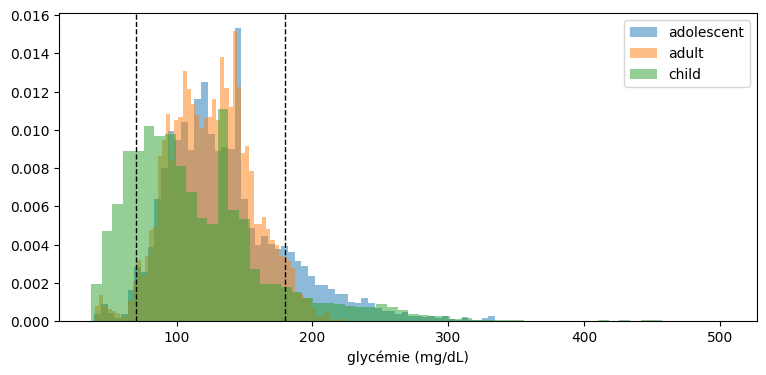

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for c, g in df.groupby('category'):
    ax.hist(g['bg'], bins=60, alpha=0.5, label=c, density=True)
for v in (config.BG_LOW, config.BG_HIGH):
    ax.axvline(v, color='k', ls='--', lw=1)
ax.set_xlabel('glycémie (mg/dL)')
ax.legend()
plt.show()

## Exemple de journée par catégorie

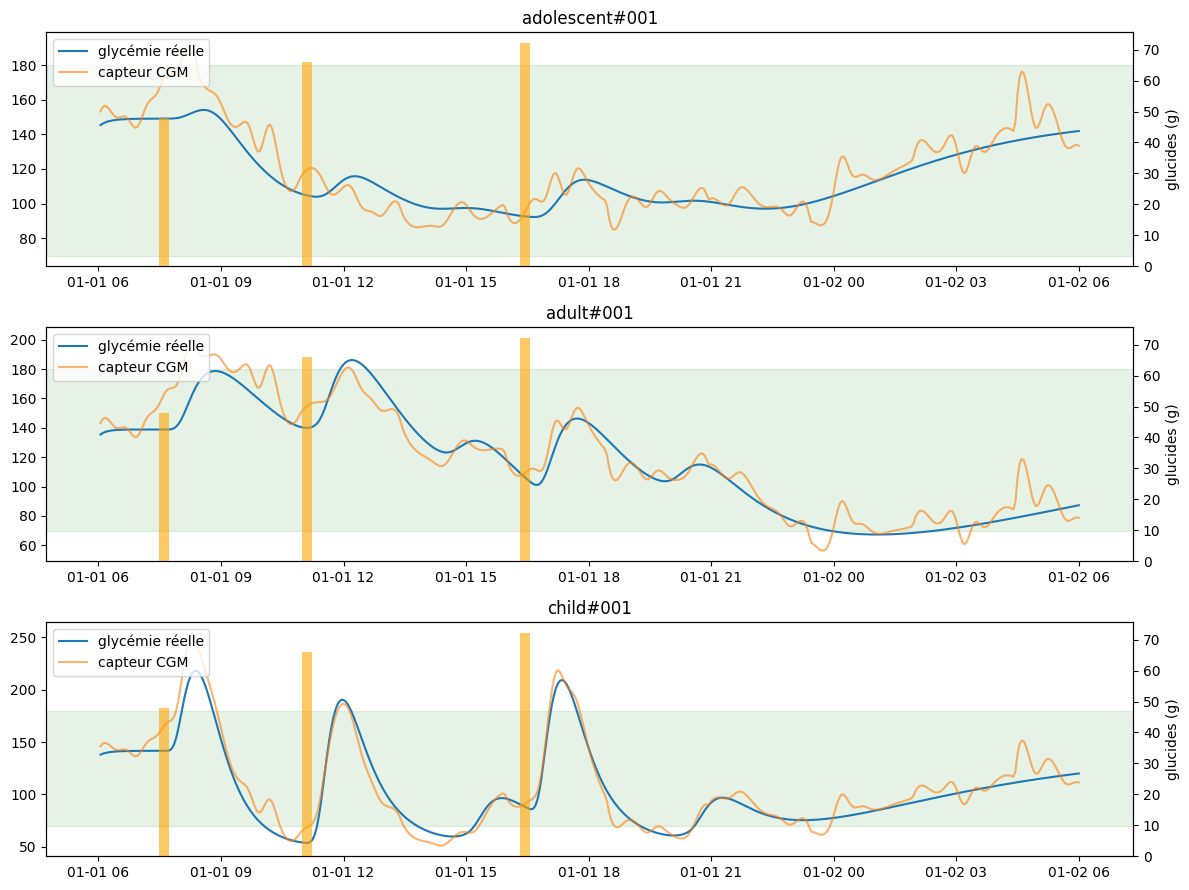

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=False)
for ax, cat in zip(axes, config.CATEGORIES):
    p = f'{cat}#001'
    g = df[(df.patient == p) & (df.day == 0)]
    ax.axhspan(config.BG_LOW, config.BG_HIGH, color='g', alpha=0.1)
    ax.plot(g['time'], g['bg'], label='glycémie réelle')
    ax.plot(g['time'], g['cgm'], alpha=0.6, label='capteur CGM')
    ax2 = ax.twinx()
    ax2.bar(g['time'], g['cho'], width=0.01, color='orange', alpha=0.6)
    ax2.set_ylabel('glucides (g)')
    ax.set_title(p)
    ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

## Bruit du capteur

Écart entre la mesure CGM (ce que voit le contrôleur) et la vraie glycémie.

count    41170.00
mean         0.55
std         10.87
min        -34.26
25%         -6.15
50%         -0.31
75%          6.16
max         51.90
dtype: float64


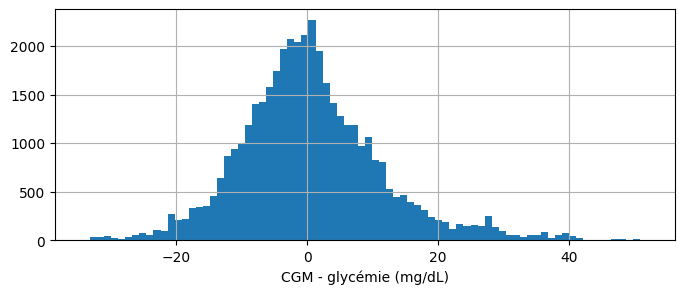

In [7]:
err = df['cgm'] - df['bg']
print(err.describe().round(2))
err.hist(bins=80, figsize=(8, 3))
plt.xlabel('CGM - glycémie (mg/dL)')
plt.show()

## Réponse aux repas

Hausse maximale de la glycémie dans les 3 h suivant un repas, selon la quantité de glucides.

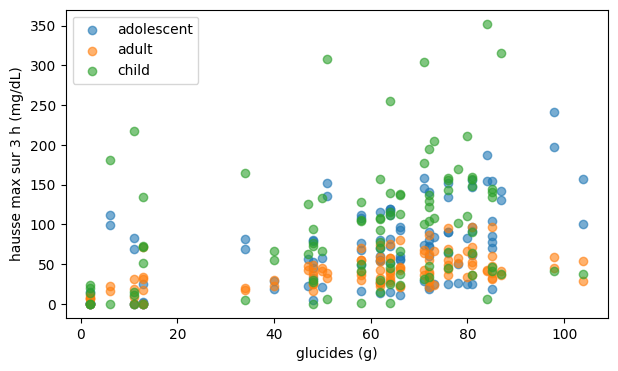

,carbs,rise
category,,
adolescent,58.0,70.9
adult,58.0,40.5
child,57.6,93.5


In [8]:
rows = []
for (p, d), g in df.groupby(['patient', 'day']):
    g = g.reset_index(drop=True)
    for i in g.index[g['cho'] > 0]:
        win = g.loc[i:i + 60]
        rows.append({'patient': p, 'category': p.split('#')[0], 'carbs': g.loc[i, 'cho'], 'rise': win['bg'].max() - g.loc[i, 'bg']})
meals = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7, 4))
for c, g in meals.groupby('category'):
    ax.scatter(g['carbs'], g['rise'], label=c, alpha=0.6)
ax.set_xlabel('glucides (g)')
ax.set_ylabel('hausse max sur 3 h (mg/dL)')
ax.legend()
plt.show()
meals.groupby('category')[['carbs', 'rise']].mean().round(1)

## Performance de la référence par patient

Temps dans la cible (70–180 mg/dL) et en hypoglycémie avec le contrôleur basal-bolus.

In [9]:
perf = df.groupby(['patient', 'category', 'split']).apply(lambda g: pd.Series({'tir': ((g.bg >= 70) & (g.bg <= 180)).mean() * 100, 'tbr': (g.bg < 70).mean() * 100, 'tar': (g.bg > 180).mean() * 100})).reset_index()
perf.groupby('category')[['tir', 'tbr', 'tar']].mean().round(1)

,tir,tbr,tar
category,,,
adolescent,82.2,2.4,15.4
adult,93.0,2.4,4.5
child,69.1,19.2,11.7


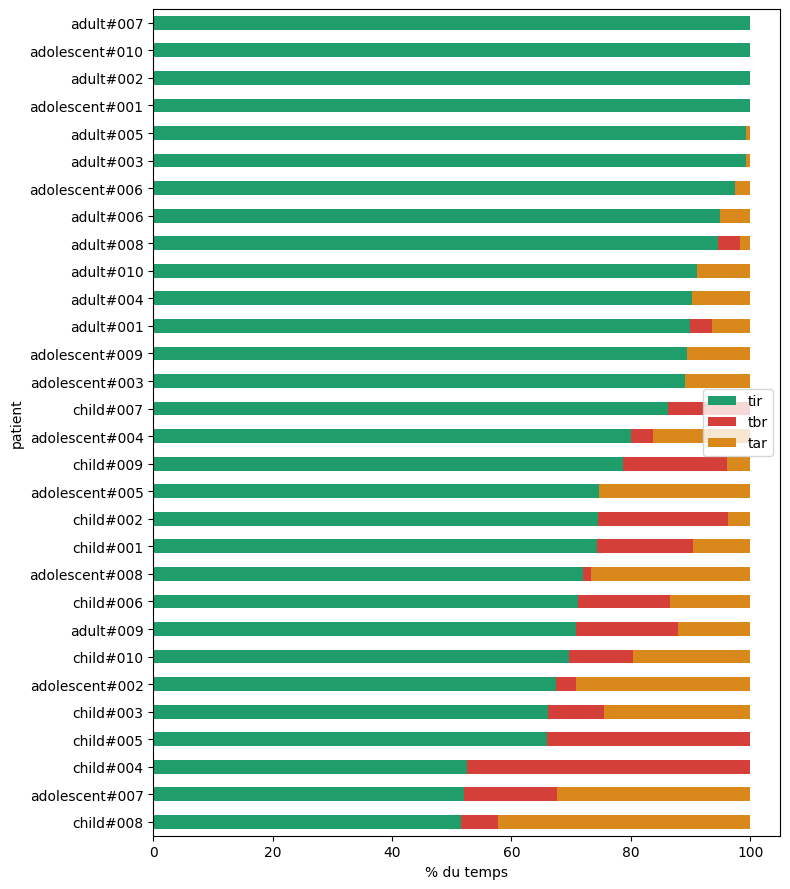

In [10]:
ax = perf.sort_values('tir').plot.barh(x='patient', y=['tir', 'tbr', 'tar'], stacked=True, figsize=(8, 9), color=['#1f9d6b', '#d43f3a', '#d9891c'])
ax.set_xlabel('% du temps')
plt.tight_layout()
plt.show()

## Variables d'entrée de l'agent (patients d'entraînement uniquement)

La normalisation est calculée sur ces données seulement, pour éviter toute fuite vers la validation et le test.

In [11]:
feats = pd.read_csv(config.DATA_DIR / 'features_train.csv')
feats.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
cgm_t-33,24822.0,124.523,39.698,39.000,97.368,121.586,146.890,275.413
cgm_t-30,24822.0,124.450,39.728,39.000,97.302,121.478,146.877,275.413
cgm_t-27,24822.0,124.376,39.758,39.000,97.195,121.374,146.867,275.413
cgm_t-24,24822.0,124.301,39.787,39.000,97.107,121.263,146.812,275.413
cgm_t-21,24822.0,124.223,39.818,39.000,96.991,121.138,146.787,275.413
cgm_t-18,24822.0,124.143,39.849,39.000,96.879,120.968,146.757,275.413
cgm_t-15,24822.0,124.060,39.882,39.000,96.763,120.835,146.718,275.413
cgm_t-12,24822.0,123.976,39.916,39.000,96.688,120.686,146.659,275.413
cgm_t-9,24822.0,123.889,39.951,39.000,96.609,120.536,146.614,275.413
cgm_t-6,24822.0,123.800,39.987,39.000,96.491,120.429,146.584,275.413


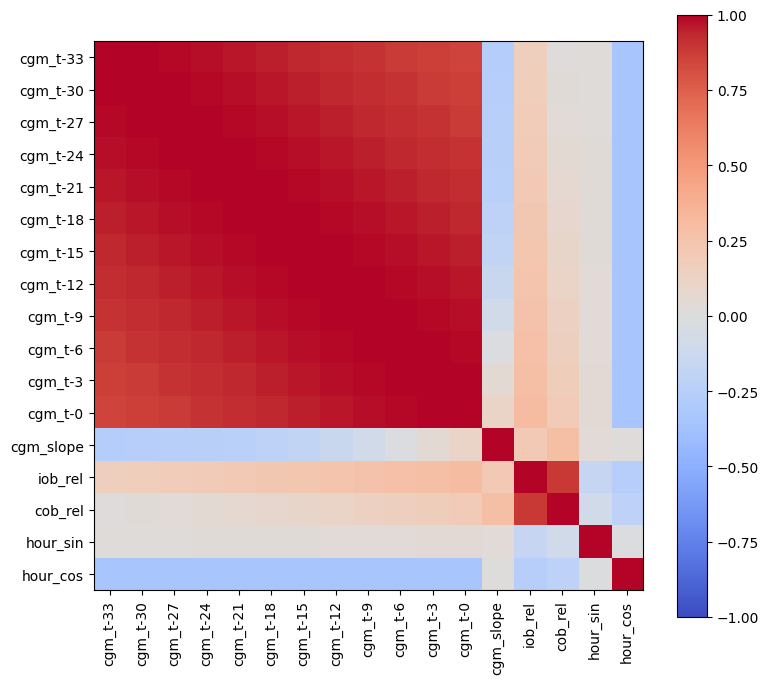

In [12]:
corr = feats.corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
fig.colorbar(im)
plt.tight_layout()
plt.show()